# Set up

In [1]:
!nvidia-smi -L
!pip install -q easyocr python-docx pymupdf rank-bm25 pyvi sentence-transformers openai opencv-python-headless
!pip install -q --no-deps vietocr
!pip install -q einops gdown prefetch_generator


GPU 0: Tesla T4 (UUID: GPU-e7e38df5-2922-049c-ebeb-b9ce1e691cf7)
GPU 1: Tesla T4 (UUID: GPU-1d6516e2-3ab4-d557-caf4-0e8f3055613b)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 5.0 MB/s eta 0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 74.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.5/8.5 MB 88.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 46.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
vietocr 0.3.13 requires imgaug==0.4.0, which is not installed.
vietocr 0.3.13 requires lmdb>=1.0.0, which is not installed.
vietocr 0.3.13 requires albumentations==1.4.2, but you have albumentations 2.0.8 which is incompatible.
vietocr 0.3.13 requires einops==0.2.0, but you have einops 0.8.2 which is incompa

In [2]:
import os, re, gc, io, json, time, random, unicodedata, urllib.request
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np, pandas as pd, torch, cv2, fitz, docx
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 42

ROOT  = Path("/kaggle/input/datasets/trnphcv")
TMP = Path("/kaggle/working/")
RAW   = ROOT / "raw123"
OUT   = TMP / "out"
CACHE = TMP / "ocr_cache"
for p in (RAW, OUT, CACHE):
    p.mkdir(parents=True, exist_ok=True)

DOCS = [
    {"file": "blld_2019.pdf", "so_hieu": "45/2019/QH14", "title": "Bộ luật Lao động 2019", "active": True, "replaced_by": ""},
    # {"file": "blld_2012.docx", "so_hieu": "10/2012/QH13", "title": "Bộ luật Lao động 2012", "active": False, "replaced_by": "45/2019/QH14"},
]

CFG = dict(
    dpi=200,                 # như code cũ
    force_ocr=False,         # True = bỏ qua text layer có sẵn
    deskew=True,             # chỉnh nghiêng trang trước khi OCR
    header_ratio=0.05,       # cắt 5% trên/dưới (code cũ 8%, luật nên để nhỏ để không mất chữ)
    footer_ratio=0.05,
    y_tol_px=30,             # Y_TOLERANCE ở 200 dpi, tự scale theo dpi
    det_min_size=10,
    det_width_ths=0.7,
    vietocr_model="vgg_transformer",
    vietocr_weights="https://vocr.vn/data/vietocr/vgg_transformer.pth",
    beamsearch=False,
    rec_batch=32,            # T4 15GB chạy tốt
    flag_prob=0.80,          # dòng có xác suất < 0.8 sẽ tô vàng trong DOCX
    use_review=True,         # Cell 5 ưu tiên đọc file *_review.docx đã sửa
)

FINDINGS, DFS = {}, {}

def free_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def parse_json(s):
    s = re.sub(r"```(?:json)?", "", s or "")
    m = re.search(r"\{.*\}", s, re.S)
    if not m:
        raise ValueError(f"Không parse được JSON: {s[:200]}")
    return json.loads(m.group())

print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
print("Có trong raw/:", sorted(p.name for p in RAW.iterdir()))
for d in DOCS:
    print("✅" if (RAW / d["file"]).exists() else "❌ THIẾU", d["file"])


Device: cuda | Tesla T4
Có trong raw/: ['blld_2019.pdf']
✅ blld_2019.pdf


# LLM 

In [16]:
from kaggle_secrets import UserSecretsClient
from openai import OpenAI
import time

# Khởi tạo client để đọc các biến bảo mật trong Kaggle
user_secrets = UserSecretsClient()

# Lấy các Secret key (Nhớ khai báo chúng trong mục Add-ons -> Secrets của Kaggle)
GROQ_API_KEY = user_secrets.get_secret("GROQ_API_KEY")
GEMINI_API_KEY = user_secrets.get_secret("GEMINI_API_KEY")

llm = OpenAI(
    api_key=GROQ_API_KEY, 
    base_url="https://api.groq.com/openai/v1"
)
LLM_MODEL = "openai/gpt-oss-120b" # Lưu ý: Groq không có model này, bạn có thể phải dùng llama3-70b-8192 hoặc mixtral
# LLM_MODEL = "qwen/qwen3.8-27b"
judge_llm = OpenAI(
    api_key=GEMINI_API_KEY,
    base_url="https://generativelanguage.googleapis.com/v1beta/openai/"
)
JUDGE_MODEL = "gemini-3.5-flash-lite" # Hiện Gemini OpenAI compatibility API gọi qua tên 'gemini-1.5-flash'

RETRYABLE = ("429", "500", "502", "503", "504", "timeout", "overloaded")

def chat(prompt, system=None, temperature=0, client=None, model=None, retries=6):
    client, model = client or llm, model or LLM_MODEL
    msgs = ([{"role": "system", "content": system}] if system else []) + [{"role": "user", "content": prompt}]
    extra = {"reasoning_effort": "low"} if "gpt-oss" in model else {}
    for attempt in range(retries):
        try:
            r = client.chat.completions.create(model=model, messages=msgs, temperature=temperature, **extra)
            return r.choices[0].message.content or ""
        except Exception as e:
            if any(x in str(e).lower() for x in RETRYABLE) and attempt < retries - 1:
                time.sleep(min(60, 10 * (attempt + 1)))
                continue
            raise

for name, c, m in [("Groq", llm, LLM_MODEL), ("Gemini", judge_llm, JUDGE_MODEL)]:
    try:
        print(f"{name}:", chat("Giải thích RAG trong 1 câu.", client=c, model=m)[:200])
    except Exception as e:
        print(f"{name} lỗi:", e)

Groq: RAG (Retrieval-Augmented Generation) là kỹ thuật kết hợp việc truy xuất thông tin từ cơ sở dữ liệu bên ngoài với khả năng tạo văn bản của mô hình ngôn ngữ lớn để cung cấp các câu trả lời chính xác và 
Gemini: **RAG** (Retrieval-Augmented Generation) là kỹ thuật **kết hợp khả năng tìm kiếm tài liệu bên ngoài với mô hình AI** để tạo ra câu trả lời chính xác, cập nhật và ít bịa đặt hơn.


# OCR

In [4]:
import re, unicodedata, urllib.request
from pathlib import Path
import numpy as np, cv2, fitz, torch
from PIL import Image
import easyocr
from vietocr.tool.config import Cfg
from vietocr.tool.predictor import Predictor

VI_LOWER = set("aàáảãạăằắẳẵặâầấẩẫậbcdđeèéẻẽẹêềếểễệfghiìíỉĩịjklmnoòóỏõọôồốổỗộơờớởỡợ"
               "pqrstuùúủũụưừứửữựvwxyỳýỷỹỵz")
VI_UPPER = "A-ZĐÀÁẢÃẠĂẰẮẲẴẶÂẦẤẨẪẬÈÉẺẼẸÊỀẾỂỄỆÌÍỈĨỊÒÓỎÕỌÔỒỐỔỖỘƠỜỚỞỠỢÙÚỦŨỤƯỪỨỬỮỰỲÝỶỸỴ"

# Tham số mới (có thể ghi đè trong Cell 1)
CFG.setdefault("vietocr_max_width", 512)   # chiều rộng tối đa VietOCR nhận (sau khi co về cao 32px)
CFG.setdefault("seg_gap_ratio", 2.5)       # khoảng trống > 2.5 × cao chữ → tách đoạn (cột, chữ ký)
CFG.setdefault("line_tol_ratio", 0.6)      # gộp dòng: lệch tâm ≤ 60% chiều cao chữ

# =====================================================================
# 1. Chuẩn hoá & hậu xử lý chữ
# =====================================================================
def norm_text(t):
    t = unicodedata.normalize("NFC", t or "")
    for a, b in {"\u00d0": "Đ", "\u0189": "Đ", "\u00f0": "đ", "\xa0": " ", "\u200b": "", "\t": " "}.items():
        t = t.replace(a, b)
    return re.sub(r" {2,}", " ", t).strip()

RE_FIX_DIEU  = re.compile(r"^[ \t]*(?:ĐIỀU|[ĐD][iìíỉĩịl1][eêềếểễệèéẻẽẹ][uưụ])[ \t]*(?=\d)", re.M | re.I)
RE_FIX_KHOAN = re.compile(rf"^(\d{{1,2}})[ \t]*[,:;]?[ \t]+(?=[{VI_UPPER}])", re.M)   # "1 Lập" -> "1. Lập"

# "p pháp" -> "pháp": 1 phụ âm lẻ đứng trước từ bắt đầu bằng chính nó (trừ "điểm đ ...")
RE_FRAG = re.compile(r"(?<!điểm )(?<!\w)([bcdđghklmnpqrstvx]) (?=\1\w)", re.I)

OCR_FIX = {   # lỗi hay gặp — bổ sung dần khi rà soát file review
    "quân lý": "quản lý", "lạo động": "lao động", "thay đối": "thay đổi",
    "Uy ban": "Ủy ban", "nhân dẫn": "nhân dân", "TUYỀN DỤNG": "TUYỂN DỤNG",
    "số quản lý lao động": "sổ quản lý lao động",
}
RE_DUP = re.compile(r"\b(\w{2,})\s+\1\b", re.I)
REDUP_OK = {"từ", "ngày", "người", "đời", "nhà", "ai", "nhiều"}   # lặp hợp lệ

def fix_ocr_text(t):
    t = RE_FRAG.sub("", t)
    for k, v in OCR_FIX.items():
        t = re.sub(rf"\b{re.escape(k)}\b", v, t)
    return t

def ocr_postfix(t):
    t = fix_ocr_text(norm_text(t))
    t = RE_FIX_DIEU.sub("Điều ", t)
    return RE_FIX_KHOAN.sub(r"\1. ", t)

def has_dup_word(t):
    return any(m.group(1).lower() not in REDUP_OK for m in RE_DUP.finditer(t))

def text_layer_ok(t, min_letters=80):
    letters = [c for c in t.lower() if c.isalpha()]
    if len(letters) < min_letters:
        return False
    vi = sum(c in VI_LOWER for c in letters) / len(letters)
    acc = sum(c in VI_LOWER and not c.isascii() for c in letters) / len(letters)
    return vi > 0.97 and acc > 0.08

# =====================================================================
# 2. Ảnh (giữ nguyên — đã kiểm chứng còn nghiêng ≤ 0.1°)
# =====================================================================
def render_page(page, dpi):
    pix = page.get_pixmap(dpi=dpi, colorspace=fitz.csRGB, alpha=False)
    return np.frombuffer(pix.samples, np.uint8).reshape(pix.height, pix.width, 3).copy()

def deskew(gray, max_angle=3.0, step=0.1):
    small = cv2.resize(gray, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_AREA)
    _, bw = cv2.threshold(small, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    h, w = bw.shape
    best, best_s = 0.0, -1
    for a in np.arange(-max_angle, max_angle + 1e-6, step):
        r = cv2.warpAffine(bw, cv2.getRotationMatrix2D((w / 2, h / 2), a, 1), (w, h), flags=cv2.INTER_NEAREST)
        s = np.var(r.sum(1))
        if s > best_s:
            best, best_s = a, s
    if abs(best) < 0.05:
        return gray
    H, W = gray.shape
    return cv2.warpAffine(gray, cv2.getRotationMatrix2D((W / 2, H / 2), best, 1), (W, H),
                          flags=cv2.INTER_CUBIC, borderValue=255)

# =====================================================================
# 3. Khởi tạo model
# =====================================================================
def build_ocr():
    if DEVICE == "cuda":
        torch.backends.cudnn.benchmark = True
    cfg = Cfg.load_config_from_name(CFG["vietocr_model"])
    w = Path("/content/weights") / f"{CFG['vietocr_model']}.pth"
    try:
        if not w.exists():
            w.parent.mkdir(parents=True, exist_ok=True)
            print("⏳ Tải trọng số VietOCR ...")
            urllib.request.urlretrieve(CFG["vietocr_weights"], w)
        cfg["weights"] = str(w)
    except Exception as e:
        print(f"⚠️ Không tải được từ vocr.vn ({e}) → dùng link mặc định của VietOCR")
    cfg["cnn"]["pretrained"] = False
    cfg["device"] = "cuda:0" if DEVICE == "cuda" else "cpu"
    cfg["predictor"]["beamsearch"] = CFG["beamsearch"]
    cfg["dataset"]["image_max_width"] = CFG["vietocr_max_width"]
    pred = Predictor(cfg)
    reader = easyocr.Reader(["vi"], gpu=DEVICE == "cuda", recognizer=False,
                            quantize=False, cudnn_benchmark=True, verbose=False)
    print(f"✅ VietOCR {CFG['vietocr_model']} (max_w={CFG['vietocr_max_width']}) + EasyOCR detector | {DEVICE}")
    return pred, reader

PRED, READER = None, None
def get_ocr():
    global PRED, READER
    if PRED is None:
        PRED, READER = build_ocr()
    return PRED, READER

# =====================================================================
# 4. Nhận dạng theo batch
# =====================================================================
def recognize(crops):
    pred, _ = get_ocr()
    texts, probs, bs = [], [], CFG["rec_batch"]
    for s in range(0, len(crops), bs):
        b = crops[s:s + bs]
        try:
            t, p = pred.predict_batch(b, return_prob=True)
        except TypeError:
            t = pred.predict_batch(b); p = [1.0] * len(t)
        except Exception as e:
            print(f"  [Warning] Batch lỗi: {str(e)[:100]} → đọc từng ảnh")
            t, p = [], []
            for im in b:
                try:
                    x, q = pred.predict(im, return_prob=True)
                except Exception:
                    x, q = "", 0.0
                t.append(x); p.append(q)
        texts += list(t); probs += [float(x) for x in p]
    return texts, probs

RE_ODD = re.compile(r"[^\w\s.,;:!?()\[\]\"'“”‘’/%&+\-–—…°§]")

def line_flags(text, prob):
    f = []
    if prob < CFG["flag_prob"]:
        f.append(f"p={prob:.2f}")
    if RE_ODD.search(text):
        f.append("ký tự lạ")
    if has_dup_word(text):
        f.append("lặp từ")
    return f

# =====================================================================
# 5. Khung chữ → dòng → đoạn
# =====================================================================
def to_xyxy(horizontal_list, free_list):
    """EasyOCR detect(): horizontal = [x_min, x_max, y_min, y_max], free = 4 đỉnh."""
    boxes = [[b[0], b[2], b[1], b[3]] for b in horizontal_list]
    for p in free_list:
        p = np.array(p)
        boxes.append([p[:, 0].min(), p[:, 1].min(), p[:, 0].max(), p[:, 1].max()])
    return [list(map(int, b)) for b in boxes]

def group_lines(boxes, tol):
    """Gom khung thành dòng: so với tâm TRUNG BÌNH của dòng (không bị trôi)."""
    lines = []
    for b in sorted(boxes, key=lambda b: (b[1] + b[3]) / 2):
        yc = (b[1] + b[3]) / 2
        if lines and abs(yc - lines[-1]["yc"]) <= tol:
            L = lines[-1]; L["boxes"].append(b)
            L["yc"] = float(np.mean([(x[1] + x[3]) / 2 for x in L["boxes"]]))
        else:
            lines.append({"yc": yc, "boxes": [b]})
    return [sorted(L["boxes"], key=lambda b: b[0]) for L in lines]

def line_segments(line_boxes, max_ratio, gap_ratio):
    """Gộp khung trong 1 dòng thành đoạn liền (khung chồng nhau tự hợp nhất → hết lồng chữ)."""
    h = float(np.median([b[3] - b[1] for b in line_boxes]))
    segs, cur = [], None
    for b in line_boxes:
        if cur is None:
            cur = list(b); continue
        gap = b[0] - cur[2]
        new = [cur[0], min(cur[1], b[1]), max(cur[2], b[2]), max(cur[3], b[3])]
        if gap > gap_ratio * h or (new[2] - new[0]) / max(1, new[3] - new[1]) > max_ratio:
            segs.append(cur); cur = list(b)
        else:
            cur = new
    segs.append(cur)
    return segs

def crop_seg(img, s, pad_x=4, pad_y=3):
    H, W = img.shape[:2]
    x1, y1 = max(0, s[0] - pad_x), max(0, s[1] - pad_y)
    x2, y2 = min(W, s[2] + pad_x), min(H, s[3] + pad_y)
    return Image.fromarray(img[y1:y2, x1:x2])

def join_segments(texts):
    """Nối các đoạn trong 1 dòng; bỏ từ lặp ngay tại chỗ nối ('... luật' + 'luật ...')."""
    words = []
    for t in texts:
        w = t.split()
        if not w:
            continue
        if words and w[0].lower() == words[-1].lower() and w[0].lower() not in REDUP_OK:
            w = w[1:]
        words += w
    return " ".join(words)

# =====================================================================
# 6. OCR 1 trang
# =====================================================================
def ocr_page(gray):
    """gray: ảnh xám đã deskew. Trả về list {bbox, text, prob, flags} theo thứ tự đọc."""
    _, reader = get_ocr()
    H, W = gray.shape
    rgb = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)

    # 1) Detect
    hor, free = reader.detect(rgb, min_size=CFG["det_min_size"], width_ths=CFG["det_width_ths"])
    boxes = to_xyxy(hor[0] if hor else [], free[0] if free else [])

    # 2) Lọc header/footer + khung quá nhỏ
    y_min, y_max = H * CFG["header_ratio"], H * (1 - CFG["footer_ratio"])
    boxes = [b for b in boxes
             if y_min <= (b[1] + b[3]) / 2 <= y_max and b[2] - b[0] >= 4 and b[3] - b[1] >= 4]
    if not boxes:
        return []

    # 3) Gom dòng — ngưỡng theo chiều cao chữ thực tế, không vượt y_tol_px cũ
    med_h = float(np.median([b[3] - b[1] for b in boxes]))
    tol = min(CFG["y_tol_px"] * CFG["dpi"] / 200, CFG["line_tol_ratio"] * med_h)
    lines = group_lines(boxes, tol)

    # 4) Gộp đoạn: tỉ lệ rộng/cao không vượt khả năng của VietOCR (ảnh cao 32px)
    max_ratio = 0.9 * CFG["vietocr_max_width"] / 32
    seg_lines = [line_segments(L, max_ratio, CFG["seg_gap_ratio"]) for L in lines]
    crops = [crop_seg(rgb, s) for segs in seg_lines for s in segs]

    # 5) Nhận dạng tất cả đoạn của trang trong 1 lượt batch
    texts, probs = recognize(crops)

    # 6) Ghép lại theo dòng
    out, k = [], 0
    for segs in seg_lines:
        n = len(segs)
        t_seg, p_seg = [x.strip() for x in texts[k:k + n]], probs[k:k + n]
        k += n
        keep = [i for i, x in enumerate(t_seg) if x]
        if not keep:
            continue
        text = ocr_postfix(join_segments([t_seg[i] for i in keep]))
        if not text:
            continue
        prob = min(p_seg[i] for i in keep)
        bbox = [min(s[0] for s in segs), min(s[1] for s in segs),
                max(s[2] for s in segs), max(s[3] for s in segs)]
        out.append({"bbox": bbox, "text": text, "prob": round(prob, 3),
                    "flags": line_flags(text, prob)})
    return out


In [5]:
from docx import Document
from docx.shared import Cm, Pt, RGBColor
from docx.oxml import OxmlElement
from docx.oxml.ns import qn

def _cache_dir(path):
    d = CACHE / f"{path.stem}_{path.stat().st_size}_vietocr_{CFG['dpi']}"
    d.mkdir(parents=True, exist_ok=True)
    return d

def clear_cache(path, pages=None):
    """Xoá cache toàn bộ, hoặc các trang (đánh số từ 1), để OCR lại."""
    d = _cache_dir(path)
    files = list(d.glob("*")) if pages is None else [d / f"{p - 1:04d}.{e}" for p in pages for e in ("json", "jpg")]
    for f in files:
        Path(f).unlink(missing_ok=True)

def ocr_pdf(path, pages=None):
    """OCR PDF, cache từng trang. pages = list index (từ 0) để chạy thử."""
    cdir, recs = _cache_dir(path), {}
    with fitz.open(path) as pdf:
        targets = list(range(len(pdf))) if pages is None else list(pages)
        todo = []
        for i in targets:
            f = cdir / f"{i:04d}.json"
            if f.exists():
                recs[i] = json.loads(f.read_text("utf-8")); continue
            txt = norm_text(pdf[i].get_text("text", sort=True))
            if not CFG["force_ocr"] and text_layer_ok(txt):
                recs[i] = {"page": i, "method": "text", "lines": [{"bbox": None, "text": txt, "prob": 1.0, "flags": []}]}
                f.write_text(json.dumps(recs[i], ensure_ascii=False), "utf-8")
            else:
                todo.append(i)

        if todo:
            get_ocr()
            print(f"🚀 OCR {len(todo)} trang ...")
            t0 = time.time()
            bar = tqdm(todo, desc="OCR")
            for i in bar:
                gray = cv2.cvtColor(render_page(pdf[i], CFG["dpi"]), cv2.COLOR_RGB2GRAY)
                if CFG["deskew"]:
                    gray = deskew(gray)
                cv2.imwrite(str(cdir / f"{i:04d}.jpg"), gray, [cv2.IMWRITE_JPEG_QUALITY, 85])
                recs[i] = {"page": i, "method": "ocr", "lines": ocr_page(gray)}
                (cdir / f"{i:04d}.json").write_text(json.dumps(recs[i], ensure_ascii=False), "utf-8")
                bar.set_postfix(s_trang=f"{(time.time() - t0) / (bar.n + 1):.1f}")
            dt = time.time() - t0
            vram = f" | VRAM {torch.cuda.max_memory_allocated() / 1e9:.1f}GB" if DEVICE == "cuda" else ""
            print(f"✅ OCR xong: {dt:.0f}s ({dt / len(todo):.1f}s/trang){vram}")
    return [recs[i] for i in targets]

def page_text(rec):
    return "\n".join(l["text"] for l in rec["lines"] if l["text"].strip())

def ocr_report(recs):
    lines = [l for r in recs for l in r["lines"]]
    flagged = [l for l in lines if l["flags"]]
    print(f"{dict(Counter(r['method'] for r in recs))} | {len(lines)} dòng | "
          f"xác suất TB {np.mean([l['prob'] for l in lines]):.3f} | "
          f"{len(flagged)} dòng gắn cờ ({len(flagged) / max(1, len(lines)):.1%})")

# ---------- DOCX ----------
def _setup(doc, size=13):
    s = doc.sections[0]
    s.left_margin = s.right_margin = s.top_margin = s.bottom_margin = Cm(1.5)
    st = doc.styles["Normal"]; st.font.name = "Times New Roman"; st.font.size = Pt(size)
    st.element.rPr.rFonts.set(qn("w:eastAsia"), "Times New Roman")

def _shade(cell, color="FFF2CC"):
    shd = OxmlElement("w:shd")
    shd.set(qn("w:val"), "clear"); shd.set(qn("w:color"), "auto"); shd.set(qn("w:fill"), color)
    cell._tc.get_or_add_tcPr().append(shd)

def export_review_docx(path, recs, overwrite=False):
    """Mỗi dòng: [mã trang.dòng | ảnh gốc + chữ OCR ngay bên dưới]. Ô vàng = cần kiểm tra."""
    out = OUT / f"{path.stem}_review.docx"
    if out.exists() and not overwrite:
        print(f"⏭️ {out.name} đã có (có thể chứa chỉnh sửa của bạn), không ghi đè. Dùng overwrite=True nếu muốn.")
        return out
    cdir, doc = _cache_dir(path), Document()
    _setup(doc, 12)
    doc.add_heading(f"Bản OCR để rà soát: {path.name}", 0)
    doc.add_paragraph("Sửa chữ ngay dưới ảnh trong cột phải. Ô vàng = VietOCR không chắc chắn. "
                      "KHÔNG xoá hàng, không sửa cột mã. Muốn bỏ một dòng thì xoá trắng chữ.")
    for r in recs:
        pno = r["page"] + 1
        doc.add_heading(f"Trang {pno}", 1)
        jpg = cdir / f"{r['page']:04d}.jpg"
        img = Image.open(jpg) if r["method"] == "ocr" and jpg.exists() else None
        tbl = doc.add_table(rows=0, cols=2); tbl.style = "Table Grid"
        for li, l in enumerate(r["lines"], 1):
            c0, c1 = tbl.add_row().cells
            c0.text = f"{pno}.{li}"
            if l["flags"]:
                run = c0.add_paragraph().add_run("⚠ " + "; ".join(l["flags"]))
                run.font.size = Pt(7); run.font.color.rgb = RGBColor(0xC0, 0, 0)
                _shade(c1)
            if img is not None and l["bbox"]:
                x0, y0, x1, y1 = l["bbox"]
                crop = img.crop((max(0, x0 - 4), max(0, y0 - 4), x1 + 4, y1 + 4))
                buf = io.BytesIO(); crop.save(buf, "JPEG", quality=65); buf.seek(0)
                width = min(16.0, crop.width / CFG["dpi"] * 2.54)        # đúng kích thước thật trên giấy
                c1.paragraphs[0].add_run().add_picture(buf, width=Cm(width))
                c1.add_paragraph(l["text"])
            else:
                c1.paragraphs[0].text = l["text"]
        for row in tbl.rows:
            row.cells[0].width, row.cells[1].width = Cm(1.8), Cm(16.2)
        doc.add_page_break()
    doc.save(out)
    print(f"💾 {out} ({out.stat().st_size / 1e6:.1f} MB)")
    return out

def read_review_docx(p):
    """Đọc lại chữ (đã sửa) theo thứ tự trang.dòng. Đoạn chứa ảnh không có chữ nên tự bị bỏ qua."""
    pages = defaultdict(list)
    for t in Document(p).tables:
        for row in t.rows:
            cells = row.cells
            if len(cells) >= 2 and (m := re.match(r"^\s*(\d+)\.(\d+)", cells[0].text)):
                txt = " ".join(x.text.strip() for x in cells[1].paragraphs if x.text.strip())
                pages[int(m.group(1))].append((int(m.group(2)), txt))
    n = max(pages) if pages else 0
    return ["\n".join(t for _, t in sorted(pages.get(i, [])) if t) for i in range(1, n + 1)]

RE_HEAD = re.compile(r"^(Chương|CHƯƠNG|Mục|MỤC|Điều)\s+\S+")
def export_text_docx(pages, out_path):
    """DOCX văn bản thuần (giống Ket_qua_OCR.docx của code cũ), in đậm Chương/Mục/Điều."""
    doc = Document(); _setup(doc)
    doc.add_heading("KẾT QUẢ OCR", 0)
    for line in "\n".join(pages).splitlines():
        if line.strip():
            doc.add_paragraph().add_run(line.strip()).bold = bool(RE_HEAD.match(line.strip()))
    doc.save(out_path); print(f"💾 {out_path}")

def load_pages(path):
    """Nguồn chữ cho Cell 5: DOCX gốc / bản review đã sửa / kết quả OCR."""
    ext = path.suffix.lower()
    if ext == ".docx":
        return [ocr_postfix("\n".join(p.text for p in docx.Document(path).paragraphs if p.text.strip()))], ["docx"]
    if ext != ".pdf":
        return [ocr_postfix(path.read_text(encoding="utf-8"))], ["txt"]
    review = OUT / f"{path.stem}_review.docx"
    if CFG["use_review"] and review.exists():
        print(f"📝 Dùng bản đã rà soát: {review.name}")
        pages = read_review_docx(review)
        return [ocr_postfix(p) for p in pages], ["review"] * len(pages)
    recs = ocr_pdf(path)
    return [ocr_postfix(page_text(r)) for r in recs], [r["method"] for r in recs]


In [6]:
pdf_path = RAW / DOCS[0]["file"]
recs = ocr_pdf(pdf_path)          # các trang đã chạy ở 4a lấy từ cache
ocr_report(recs)
review_path = export_review_docx(pdf_path, recs)
export_text_docx([page_text(r) for r in recs], OUT / f"{pdf_path.stem}_ocr_raw.docx")
# Tải review_path về, sửa, upload đè lại vào /content/out/ (giữ nguyên tên) rồi chạy Cell 5


⏳ Tải trọng số VietOCR ...


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:144: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.encoder = TransformerEncoder(


✅ VietOCR vgg_transformer (max_w=512) + EasyOCR detector | cuda
🚀 OCR 83 trang ...


OCR:   0%|          | 0/83 [00:00<?, ?it/s]

✅ OCR xong: 1267s (15.3s/trang) | VRAM 12.1GB
{'ocr': 83} | 3184 dòng | xác suất TB 0.922 | 26 dòng gắn cờ (0.8%)
💾 /kaggle/working/out/blld_2019_review.docx (43.5 MB)
💾 /kaggle/working/out/blld_2019_ocr_raw.docx


In [8]:
RE_DIEU   = re.compile(r"^(?:Điều|ĐIỀU)\s+(\d{1,4})([a-zđ]?)(\s*[.:]\s*|\s+|$)(.*)$")
RE_CHUONG = re.compile(r"^(?:Chương|CHƯƠNG)\s+([IVXLCDM]+|\d+)\b\.?\s*(.*)$")
RE_MUC    = re.compile(r"^(?:Mục|MỤC)\s+(\d+)\b\.?\s*(.*)$")
RE_KHOAN  = re.compile(r"^\d{1,3}\.\s+")
RE_DIEM   = re.compile(r"^[a-zđ]\)\s+")
RE_END    = re.compile(r"^((Bộ luật|Luật|Pháp lệnh) này (đã )?được Quốc hội|Nơi nhận|(TM|KT)\.\s|CHỦ TỊCH QUỐC HỘI)")
RE_PAGENO = re.compile(r"^\s*(trang\s*)?\d{1,4}(\s*/\s*\d{1,4})?\s*$", re.I)
RE_HEAD_FIX = re.compile(
    rf"^[ \t]*(?i:ĐIỀU|[ĐD][iìíỉĩịl1][eêềếểễệèéẻẽẹ][uưụnm])"   # chỉ phần "Điều" không phân biệt hoa/thường
    rf"[ \t]*(\d{{1,3}}[a-z]?)[ \t]*[.,;:]?[ \t]*(?=[{VI_UPPER}])",  # sau số phải là chữ IN HOA
    re.M)
HEAD_WORD_FIX = {"Thời hiện": "Thời hiệu"}   # bổ sung dần khi gặp lỗi khác

def fix_headings(t):
    t = RE_HEAD_FIX.sub(lambda m: f"Điều {m.group(1)}. ", t)
    for k, v in HEAD_WORD_FIX.items():
        t = t.replace(k, v)
    return t
def match_dieu(line):
    m = RE_DIEU.match(line)
    if not m:
        return None
    num, suf, sep, rest = m.groups()
    rest = rest.strip()
    return (num, suf, rest) if any(c in sep for c in ".:") or not rest or rest[0].isupper() else None

def heading_ok(m):
    t = m.group(2).strip()
    return not t or t.isupper()

def is_heading(l):
    return bool(match_dieu(l) or ((m := RE_CHUONG.match(l)) and heading_ok(m)) or ((m := RE_MUC.match(l)) and heading_ok(m)))

def starts_block(l):
    return is_heading(l) or bool(RE_KHOAN.match(l) or RE_DIEM.match(l)) or l[:1] in "-–•+"

def strip_headers(pages, min_ratio=0.3):
    key = lambda l: re.sub(r"\d+", "#", l.strip().lower())
    rep = set()
    if len(pages) >= 4:
        cnt = Counter()
        for p in pages:
            ls = [l for l in p.splitlines() if l.strip()]
            cnt.update({key(l) for l in ls[:3] + ls[-3:]})
        rep = {k for k, c in cnt.items() if c >= min_ratio * len(pages) and len(k) < 80}
    return ["\n".join(l for l in p.splitlines() if l.strip() and key(l) not in rep and not RE_PAGENO.match(l))
            for p in pages]

def reflow(text):
    out = []
    for line in (l.strip() for l in text.splitlines()):
        if not line:
            continue
        if out:
            prev = out[-1]
            join = (not starts_block(line) and not line.isupper() and not prev.isupper()
                    and not re.search(r"[.;:!?]$", prev))
            if join and is_heading(prev) and not line[:1].islower():
                join = False
            if join:
                out[-1] = f"{prev} {line}"; continue
        out.append(line)
    return "\n".join(out)

def parse_articles(text, doc, max_gap=5):
    lines = reflow(text).splitlines()
    arts, cur, chapter, last, i = [], None, "", 0, 0
    while i < len(lines):
        line = lines[i]; i += 1
        if arts and RE_END.match(line):
            break
        if (m := RE_CHUONG.match(line)) and heading_ok(m):
            title = m.group(2).strip()
            if not title and i < len(lines) and lines[i].isupper():
                title = lines[i]; i += 1
            chapter, cur = f"Chương {m.group(1)}. {title}".strip(". "), None
            continue
        if (m := RE_MUC.match(line)) and heading_ok(m):
            if not m.group(2).strip() and i < len(lines) and lines[i].isupper():
                i += 1
            cur = None
            continue
        if d := match_dieu(line):
            num, suf, title = d
            n = int(num)
            if last == 0 or (suf and n == last) or (last < n <= last + max_gap):
                if not title and i < len(lines) and not starts_block(lines[i]):
                    title = lines[i]; i += 1
                last = n
                cur = {"aid": f"{doc['so_hieu']}|{num}{suf}", "so_hieu": doc["so_hieu"], "doc_title": doc["title"],
                       "active": doc["active"], "replaced_by": doc["replaced_by"], "chapter": chapter,
                       "article": f"{num}{suf}", "title": title, "lines": []}
                arts.append(cur)
                continue
        if cur is not None:
            cur["lines"].append(line)
    for a in arts:
        a["text"] = "\n".join(a.pop("lines"))
    return arts

def report(arts, name, pages):
    nums = [int(re.match(r"\d+", a["article"]).group()) for a in arts]
    missing = sorted(set(range(1, max(nums) + 1)) - set(nums))
    dups = [k for k, c in Counter(a["article"] for a in arts).items() if c > 1]
    lens = [len(a["text"]) for a in arts]
    print(f"✅ {name}: {len(arts)} điều | thiếu {len(missing)}: {missing[:20]} | trùng: {dups[:10]} | "
          f"median {np.median(lens):.0f}, max {max(lens)} ký tự")
    for num in missing[:10]:
        pat = re.compile(rf"^\S{{2,8}}\s*{num}\s*[.:,]?\s")
        hits = [(pi + 1, l.strip()) for pi, p in enumerate(pages) for l in p.splitlines() if pat.match(l.strip())]
        print(f"   Điều {num}: " + (" | ".join(f"tr.{pi}: {l[:60]}" for pi, l in hits[:2]) if hits
                                   else "không thấy → tìm trong DOCX rà soát"))

ARTICLES, PAGES = [], {}
for d in DOCS:
    path = RAW / d["file"]
    if not path.exists():
        print(f"⚠️ Bỏ qua {d['file']}"); continue
    pages, methods = load_pages(path)
    pages = [fix_headings(p) for p in pages]
    PAGES[d["file"]] = pages
    print(f"\n--- {d['title']}: {len(pages)} trang | {dict(Counter(methods))}")
    arts = parse_articles("\n".join(strip_headers(pages)), d)
    if not arts:
        print(f"❌ Không tách được Điều nào từ {d['file']}"); continue
    report(arts, d["file"], pages)
    ARTICLES += arts

ART_BY_ID = {a["aid"]: a for a in ARTICLES}
if ARTICLES:
    a = ARTICLES[min(10, len(ARTICLES) - 1)]
    print(f"\nMẫu: [{a['chapter']}] Điều {a['article']}. {a['title']}\n{a['text'][:500]}")


📝 Dùng bản đã rà soát: blld_2019_review.docx

--- Bộ luật Lao động 2019: 83 trang | {'review': 83}
✅ blld_2019.pdf: 220 điều | thiếu 0: [] | trùng: [] | median 644, max 7167 ký tự

Mẫu: [Chương II. VIỆC LÀM, TUYỂN DỤNG VÀ QUẢN LÝ LAO ĐỘNG] Điều 11. Tuyển dụng lao động
1. Người sử dụng lao động có quyền trực tiếp hoặc thông qua tổ chức dịch vụ việc làm, doanh nghiệp hoạt động cho thuê lại lao động để tuyển dụng lao động theo nhu cầu của người sử dụng lao động.
2. Người lao động không phải trả chi phí cho việc tuyển dụng lao động.


# Chunk split

In [9]:
def header(a):
    ch = f" - {a['chapter']}" if a.get("chapter") else ""
    return f"{a['doc_title']} ({a['so_hieu']}){ch} - Điều {a['article']}. {a['title']}"

def _split(text, pat):
    blocks, cur = [], []
    for line in text.split("\n"):
        if pat.match(line) and cur:
            blocks.append("\n".join(cur)); cur = []
        cur.append(line)
    return blocks + (["\n".join(cur)] if cur else [])

def _pack(blocks, max_chars):
    out, buf = [], ""
    for b in blocks:
        if buf and len(buf) + len(b) + 1 > max_chars:
            out.append(buf); buf = ""
        buf = f"{buf}\n{b}" if buf else b
    return out + ([buf] if buf else [])

def split_article(text, max_chars):
    if len(text) <= max_chars:
        return [text]
    blocks = []
    for b in _split(text, RE_KHOAN):                  # ưu tiên ranh giới Khoản
        if len(b) <= max_chars:
            blocks.append(b)
        else:                                         # Khoản quá dài → tách theo Điểm
            for p in _split(b, RE_DIEM):
                blocks += [p[i:i + max_chars] for i in range(0, len(p), max_chars)]
    return _pack(blocks, max_chars)

def chunk_by_article(arts, max_chars=1800):
    return [{"text": f"{header(a)}\n{body}", "articles": [a["aid"]], "so_hieu": a["so_hieu"],
             "active": a["active"], "replaced_by": a["replaced_by"]}
            for a in arts for body in split_article(a["text"], max_chars)]

def chunk_fixed(arts, size=1000, overlap=200):
    """Baseline: cắt cố định theo ký tự."""
    chunks, by_doc = [], defaultdict(list)
    for a in arts:
        by_doc[a["so_hieu"]].append(a)
    for so_hieu, da in by_doc.items():
        full, spans = "", []
        for a in da:
            t = f"Điều {a['article']}. {a['title']}\n{a['text']}\n"
            spans.append((len(full), len(full) + len(t), a["aid"])); full += t
        for s in range(0, len(full), size - overlap):
            e = s + size
            chunks.append({"text": f"{da[0]['doc_title']}\n{full[s:e]}",
                           "articles": [aid for a0, a1, aid in spans if a0 < e and a1 > s],
                           "so_hieu": so_hieu, "active": da[0]["active"], "replaced_by": da[0]["replaced_by"]})
    return chunks

chunks_art, chunks_fix = chunk_by_article(ARTICLES), chunk_fixed(ARTICLES)
print(f"Chunk theo Điều: {len(chunks_art)} | Chunk cố định: {len(chunks_fix)}")


Chunk theo Điều: 233 | Chunk cố định: 235


# Retrieve

In [10]:
from pyvi import ViTokenizer
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer, CrossEncoder

def tokenize(text):
    text = re.sub(r"[^\w\s]", " ", unicodedata.normalize("NFC", text.lower()))
    return ViTokenizer.tokenize(text).split()

class Embedder:
    def __init__(self, name, q_prefix="", p_prefix="", segment=False, max_len=512):
        self.m = SentenceTransformer(name, device=DEVICE)
        self.m.max_seq_length = max_len
        self.q, self.p, self.segment = q_prefix, p_prefix, segment

    def _prep(self, texts, prefix):
        if self.segment:
            texts = [ViTokenizer.tokenize(t) for t in texts]
        return [prefix + t for t in texts]

    def encode_docs(self, texts):
        return self.m.encode(self._prep(texts, self.p), batch_size=32, normalize_embeddings=True, show_progress_bar=True)

    def encode_query(self, q):
        return self.m.encode(self._prep([q], self.q), normalize_embeddings=True)[0]

class Reranker:
    def __init__(self, name="BAAI/bge-reranker-v2-m3", max_len=512):
        self.m = CrossEncoder(name, max_length=max_len, device=DEVICE)
        act = getattr(self.m, "activation_fn", None) or getattr(self.m, "default_activation_function", None)
        self.need_sigmoid = act is None or isinstance(act, torch.nn.Identity)

    def predict(self, q, texts):
        s = np.asarray(self.m.predict([(q, t) for t in texts], batch_size=32), dtype=float).ravel()
        return 1 / (1 + np.exp(-s)) if self.need_sigmoid else s   # luôn đưa về [0,1] để dò ngưỡng

def rrf(rank_lists, k=60):
    s = defaultdict(float)
    for ranks in rank_lists:
        for r, i in enumerate(ranks):
            s[i] += 1 / (k + r + 1)
    return sorted(s, key=s.get, reverse=True)

class Index:
    def __init__(self, chunks, embedder=None):
        self.chunks, self.emb = chunks, embedder
        self._bm25 = BM25Okapi([tokenize(c["text"]) for c in chunks])
        self.mat = embedder.encode_docs([c["text"] for c in chunks]) if embedder else None
        self.active = np.array([c["active"] for c in chunks])

    def _top(self, scores, k, only_active):
        scores = np.array(scores, dtype=float)
        if only_active:
            scores[~self.active] = -np.inf
        return [int(i) for i in np.argsort(-scores)[:k] if np.isfinite(scores[i])]

    def bm25_ids(self, q, k, oa):  return self._top(self._bm25.get_scores(tokenize(q)), k, oa)
    def dense_ids(self, q, k, oa): return self._top(self.mat @ self.emb.encode_query(q), k, oa)

    def search(self, q, k=5, mode="dense", only_active=True, reranker=None, n_cand=30):
        if mode == "bm25":
            ids = self.bm25_ids(q, k, only_active)
        elif mode == "dense":
            ids = self.dense_ids(q, k, only_active)
        else:
            ids = rrf([self.bm25_ids(q, n_cand, only_active), self.dense_ids(q, n_cand, only_active)])
            if mode == "rerank":
                cand = ids[:n_cand]
                s = reranker.predict(q, [self.chunks[i]["text"] for i in cand])
                return [{**self.chunks[cand[j]], "score": float(s[j])} for j in np.argsort(-s)[:k]]
            ids = ids[:k]
        return [{**self.chunks[i], "score": None} for i in ids]

def run_eval(index, qa, k=5, **kw):
    rows = []
    for it in tqdm(qa, leave=False):
        res = index.search(it["question"], k=k, **kw)
        rank = next((i + 1 for i, c in enumerate(res) if it["aid"] in c["articles"]), np.nan)
        rows.append({**it, "rank": rank, "got": [c["articles"][0] for c in res]})
    return pd.DataFrame(rows)

def summarize(df, name, k=5):
    hit = df["rank"].notna()
    return {"config": name, f"recall@{k}": round(hit.mean(), 3), f"mrr@{k}": round((1 / df["rank"]).fillna(0).mean(), 3),
            **{f"recall_{t}": round(hit[df.type == t].mean(), 3) for t in sorted(df.type.unique())}}


# Evaluate

In [12]:
QA_PATH = OUT / "qa_synthetic.jsonl"
GEN_PROMPT = """Đây là một điều luật:
{text}

Viết 2 câu hỏi mà câu trả lời nằm trong điều luật này:
- "formal": câu hỏi rõ ràng, dùng thuật ngữ pháp lý
- "casual": câu hỏi như người lao động bình thường hỏi trên mạng, dùng từ đời thường,
  KHÔNG lặp lại nguyên văn cụm từ trong điều luật
Không nhắc số điều hay tên văn bản. Kèm câu trả lời ngắn gọn dựa trên điều luật.
Chỉ trả về JSON: {{"formal": "...", "casual": "...", "answer": "..."}}"""

if QA_PATH.exists():
    QA_SYN = [json.loads(l) for l in open(QA_PATH, encoding="utf-8")]
else:
    pool = [a for a in ARTICLES if a["active"] and len(a["text"]) > 200]
    QA_SYN = []
    for a in tqdm(random.Random(SEED).sample(pool, min(100, len(pool)))):
        try:
            d = parse_json(chat(GEN_PROMPT.format(text=f"{header(a)}\n{a['text'][:3000]}"), temperature=0.7))
            QA_SYN += [{"question": d[t], "answer": d["answer"], "aid": a["aid"], "type": t} for t in ("formal", "casual")]
        except Exception as e:
            print("Bỏ qua:", e)
    with open(QA_PATH, "w", encoding="utf-8") as f:
        f.writelines(json.dumps(x, ensure_ascii=False) + "\n" for x in QA_SYN)

# Câu tự viết — nên bổ sung lên 30–50 câu. Bảng in ra bên dưới giúp kiểm tra số Điều có đúng không.
HANDWRITTEN = [
    ("Vợ sinh con thì được nghỉ mấy tháng?",                              "45/2019/QH14|139"),
    ("Thử việc tối đa bao lâu với kỹ sư?",                                 "45/2019/QH14|25"),
    ("Công ty bắt OT quá nhiều có vi phạm không, giới hạn là bao nhiêu?",  "45/2019/QH14|107"),
    ("Làm đủ 12 tháng được nghỉ phép bao nhiêu ngày?",                     "45/2019/QH14|113"),
    ("Muốn nghỉ việc thì phải báo trước công ty mấy ngày?",                "45/2019/QH14|35"),
    ("Công ty giữ bằng đại học bản gốc của em có đúng luật không?",        "45/2019/QH14|17"),
]
for q, aid in HANDWRITTEN:
    print(("✅" if aid in ART_BY_ID else "❌"), aid, "→", ART_BY_ID.get(aid, {}).get("title", "KHÔNG CÓ"), "|", q)
QA_MAN = [{"question": q, "answer": "", "aid": aid, "type": "manual"} for q, aid in HANDWRITTEN if aid in ART_BY_ID]

# Chia theo Điều để câu formal/casual của cùng một Điều không nằm ở cả 2 tập
aids = sorted({x["aid"] for x in QA_SYN}); random.Random(SEED).shuffle(aids)
dev_aids = set(aids[: len(aids) // 2])
QA_DEV  = [x for x in QA_SYN if x["aid"] in dev_aids]
QA_TEST = [x for x in QA_SYN if x["aid"] not in dev_aids] + QA_MAN
QA = QA_DEV + QA_TEST
print("DEV:", Counter(x["type"] for x in QA_DEV), "| TEST:", Counter(x["type"] for x in QA_TEST))

# Câu ngoài phạm vi cũng chia dev (dò ngưỡng) / test (đánh giá)
OOS_DEV = ["Cách nấu phở bò ngon?", "Giá vàng hôm nay bao nhiêu?", "Viết code Python sắp xếp mảng",
           "Nên mua iPhone hay Samsung?", "Thủ đô của Úc là gì?",
           "Thủ tục ly hôn đơn phương thế nào?", "Mua bán đất cần công chứng không?", "Thành lập công ty TNHH cần vốn bao nhiêu?"]
OOS_TEST = ["Messi sinh năm nào?", "Thời tiết Hà Nội ngày mai?", "Cách giảm cân nhanh?", "Học tiếng Anh thế nào cho hiệu quả?",
            "Vượt đèn đỏ bị phạt bao nhiêu tiền?", "Thừa kế không có di chúc chia thế nào?",
            "Đăng ký tạm trú cần giấy tờ gì?", "Tội trộm cắp tài sản bị phạt tù bao lâu?"]


  0%|          | 0/100 [00:00<?, ?it/s]

Bỏ qua: Extra data: line 5 column 4 (char 360)
✅ 45/2019/QH14|139 → Nghỉ thai sản | Vợ sinh con thì được nghỉ mấy tháng?
✅ 45/2019/QH14|25 → Thời gian thử việc | Thử việc tối đa bao lâu với kỹ sư?
✅ 45/2019/QH14|107 → Làm thêm giờ | Công ty bắt OT quá nhiều có vi phạm không, giới hạn là bao nhiêu?
✅ 45/2019/QH14|113 → Nghỉ hằng năm | Làm đủ 12 tháng được nghỉ phép bao nhiêu ngày?
✅ 45/2019/QH14|35 → Quyền đơn phương chấm đứt hợp đồng lao động của người lao động | Muốn nghỉ việc thì phải báo trước công ty mấy ngày?
✅ 45/2019/QH14|17 → Hành vi người sử dụng lao động không được làm khi giao kết, thực hiện hợp đồng lao động | Công ty giữ bằng đại học bản gốc của em có đúng luật không?
DEV: Counter({'formal': 49, 'casual': 49}) | TEST: Counter({'formal': 50, 'casual': 50, 'manual': 6})


# E1 (chunking), E2 (embedding), E3 (chế độ truy xuất)

In [13]:
# E1 — chọn cách chunk trên DEV
bge = Embedder("BAAI/bge-m3")
idx_art, idx_fix = Index(chunks_art, bge), Index(chunks_fix, bge)
res_e1 = pd.DataFrame([summarize(run_eval(idx, QA_DEV, mode=m), f"{n} | {m}")
                       for n, idx in [("chunk theo Điều", idx_art), ("chunk cố định 1000", idx_fix)]
                       for m in ["bm25", "dense"]])
display(res_e1); FINDINGS["E1_chunking"] = res_e1
del idx_fix; free_gpu()

# E2 — chọn embedding trên DEV
CANDIDATES = {
    "bge-m3": None,
    "vietnamese-bi-encoder": dict(name="bkai-foundation-models/vietnamese-bi-encoder", segment=True, max_len=256),
    "multilingual-e5-base":  dict(name="intfloat/multilingual-e5-base", q_prefix="query: ", p_prefix="passage: "),
}
res_e2 = []
for name, cfg in CANDIDATES.items():
    t0 = time.time()
    tmp = idx_art if cfg is None else Index(chunks_art, Embedder(**cfg))
    res_e2.append({**summarize(run_eval(tmp, QA_DEV, mode="dense"), name), "sec": round(time.time() - t0)})
    if cfg is not None:
        del tmp; free_gpu()
res_e2 = pd.DataFrame(res_e2); display(res_e2); FINDINGS["E2_embedding"] = res_e2

best = res_e2.sort_values("recall@5", ascending=False).iloc[0]["config"]
print("Embedding tốt nhất:", best)
if best != "bge-m3":
    del idx_art, bge; free_gpu()
    idx_art = Index(chunks_art, Embedder(**CANDIDATES[best]))

# E3 — so sánh chế độ truy xuất trên TEST
reranker = Reranker("BAAI/bge-reranker-v2-m3")   # có thể thử reranker tiếng Việt, vd "itdainb/PhoRanker"
res_e3 = []
for mode in ["bm25", "dense", "hybrid", "rerank"]:
    DFS[mode] = run_eval(idx_art, QA_TEST, mode=mode, reranker=reranker)
    res_e3.append(summarize(DFS[mode], mode))
res_e3 = pd.DataFrame(res_e3); display(res_e3); FINDINGS["E3_retrieval"] = res_e3

# Phân tích lỗi
fails = DFS["rerank"][DFS["rerank"]["rank"].isna()]
print(f"{len(fails)}/{len(QA_TEST)} câu không có trong top-5\n")
for _, f in fails.head(8).iterrows():
    exp, got = ART_BY_ID[f["aid"]], ART_BY_ID.get(f["got"][0] if f["got"] else "", {})
    print(f"❓ [{f['type']}] {f['question']}\n   cần : Điều {exp['article']}. {exp['title']}"
          f"\n   ra #1: Điều {got.get('article')}. {got.get('title')}\n")


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Batches:   0%|          | 0/8 [00:00<?, ?it/s]

Batches:   0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/98 [00:00<?, ?it/s]

  0%|          | 0/98 [00:00<?, ?it/s]

...

  0%|          | 0/106 [00:00<?, ?it/s]

  0%|          | 0/106 [00:00<?, ?it/s]

  0%|          | 0/106 [00:00<?, ?it/s]

,config,recall@5,mrr@5,recall_casual,recall_formal,recall_manual
0,bm25,0.764,0.650,0.64,0.90,0.667
1,dense,0.991,0.922,0.98,1.00,1.000
2,hybrid,0.877,0.790,0.80,0.96,0.833
3,rerank,0.953,0.919,0.92,1.00,0.833


5/106 câu không có trong top-5

❓ [casual] Nếu công ty mình có nhiều hội công đoàn, hội nào được phép đưa ra đề xuất đàm phán chung?
   cần : Điều 68. Quyền thương lượng tập thể của tổ chức đại diện người lao động tại cơ sở trong doanh nghiệp i. Tổ chức đại diện người lao động tại cơ sở có quyền yêu cầu thương lượng tập thể khi đạt tỷ lệ thành viên tối thiếu trên tổng sổ người lao động trong doanh nghiệp theo quy định của Chính phủ.
   ra #1: Điều 72. Thương lượng tập thể ngành, thương lượng tập thể có nhiều doanh nghiệp tham gia

❓ [casual] Ai mà quyết định người sẽ giúp mình giải quyết mâu thuẫn ở chỗ làm?
   cần : Điều 184. Hòa giải viên lao động
   ra #1: Điều 187. Thẩm quyền giải quyết tranh chấp lao động cá nhân

❓ [casual] Nếu mình bị nghỉ việc, công ty phải trả tiền cho mình trong bao lâu và có trường hợp nào mà thời gian này có thể lâu hơn không?
   cần : Điều 48. Trách nhiệm khi chấm dứt hợp đồng lao động
   ra #1: Điều 46. Trợ cấp thôi việc

❓ [casual] Nếu sếp tự ý cho tôi n

# E4, dò ngưỡng từ chối trên DEV và kiểm tra trên TEST

  0%|          | 0/98 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/106 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

Ngưỡng (dò trên DEV): 0.005 | TEST — từ chối nhầm: 1.9% | lọt ngoài phạm vi: 37.5%
  OUT 0.013 ⚠️ lọt Đăng ký tạm trú cần giấy tờ gì?
  OUT 0.011 ⚠️ lọt Tội trộm cắp tài sản bị phạt tù bao lâu?
  OUT 0.009 ⚠️ lọt Vượt đèn đỏ bị phạt bao nhiêu tiền?
  OUT 0.002  Messi sinh năm nào?
  OUT 0.000  Học tiếng Anh thế nào cho hiệu quả?
  OUT 0.000  Thừa kế không có di chúc chia thế nào?
  OUT 0.000  Cách giảm cân nhanh?
  OUT 0.000  Thời tiết Hà Nội ngày mai?


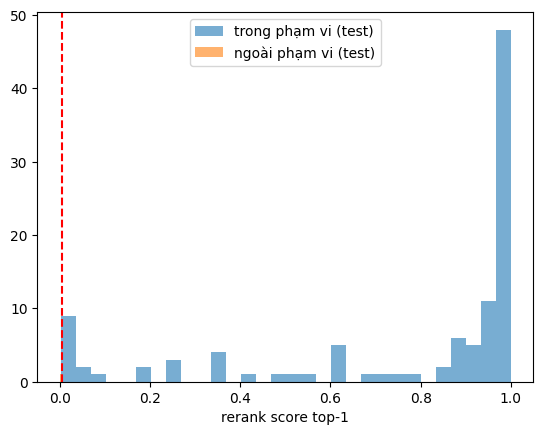

In [14]:
import matplotlib.pyplot as plt

top1 = lambda q: (idx_art.search(q, k=1, mode="rerank", reranker=reranker) or [{"score": 0.0}])[0]["score"]
score_set = lambda qs: np.array([top1(q) for q in tqdm(qs, leave=False)])

s_in_dev,  s_out_dev  = score_set([x["question"] for x in QA_DEV]),  score_set(OOS_DEV)
s_in_test, s_out_test = score_set([x["question"] for x in QA_TEST]), score_set(OOS_TEST)

ts = np.linspace(0, 1, 201)
bal = [((s_in_dev >= t).mean() + (s_out_dev < t).mean()) / 2 for t in ts]
THR = float(ts[int(np.argmax(bal))])

fr, fa = float((s_in_test < THR).mean()), float((s_out_test >= THR).mean())
print(f"Ngưỡng (dò trên DEV): {THR:.3f} | TEST — từ chối nhầm: {fr:.1%} | lọt ngoài phạm vi: {fa:.1%}")
for q, s in sorted(zip(OOS_TEST, s_out_test), key=lambda x: -x[1]):
    print(f"  OUT {s:.3f} {'⚠️ lọt' if s >= THR else ''} {q}")

plt.hist(s_in_test, bins=30, alpha=.6, label="trong phạm vi (test)")
plt.hist(s_out_test, bins=30, alpha=.6, label="ngoài phạm vi (test)")
plt.axvline(THR, color="r", ls="--"); plt.legend(); plt.xlabel("rerank score top-1"); plt.show()
FINDINGS["E4_threshold"] = {"thr": THR, "false_refusal": fr, "false_accept": fa}


# E5 (chất lượng câu trả lời) và E6 (từ chối, văn bản hết hiệu lực)

In [17]:
REFUSAL = "Không tìm thấy căn cứ pháp lý trong dữ liệu hiện có."
ANSWER_SYSTEM = f"""Bạn là trợ lý tra cứu pháp luật Việt Nam. Quy tắc:
1. CHỈ dùng thông tin trong phần Ngữ cảnh. Không dùng kiến thức bên ngoài.
2. Mỗi ý phải kèm trích dẫn dạng (Điều X, <số hiệu văn bản>).
3. Nếu Ngữ cảnh không đủ để trả lời, chỉ trả lời đúng câu: "{REFUSAL}"
4. Nếu căn cứ thuộc văn bản HẾT HIỆU LỰC, phải nói rõ và nêu văn bản thay thế.
5. Trả lời ngắn gọn, dễ hiểu."""

def rag_answer(q, k=5, only_active=True):
    hits = [h for h in idx_art.search(q, k=k, mode="rerank", reranker=reranker, only_active=only_active)
            if h["score"] >= THR]
    if not hits:
        return REFUSAL, []
    ctx = "\n\n".join(f"[{h['so_hieu']} - {'còn hiệu lực' if h['active'] else 'HẾT HIỆU LỰC, thay bởi ' + h['replaced_by']}]\n{h['text']}"
                      for h in hits)
    return chat(f"Ngữ cảnh:\n{ctx}\n\nCâu hỏi: {q}", system=ANSWER_SYSTEM), hits

JUDGE = """Đánh giá câu trả lời của một trợ lý pháp luật.
Câu hỏi: {q}
Đáp án tham chiếu: {ref}
Ngữ cảnh trợ lý được cung cấp: {ctx}
Câu trả lời của trợ lý: {ans}

Chấm 0 hoặc 1:
- "correct": câu trả lời có nội dung đúng và khớp với đáp án tham chiếu không
- "faithful": mọi thông tin trong câu trả lời đều có trong ngữ cảnh (không bịa) không
Chỉ trả về JSON: {{"correct": 0, "faithful": 0, "reason": "..."}}"""

test_syn = [x for x in QA_TEST if x["type"] != "manual"]
rows = []
for it in tqdm(random.Random(1).sample(test_syn, min(40, len(test_syn)))):
    ans, hits = rag_answer(it["question"])
    art_no = ART_BY_ID[it["aid"]]["article"]
    try:
        j = parse_json(chat(JUDGE.format(q=it["question"], ref=it["answer"], ans=ans,
                                         ctx="\n".join(h["text"][:1500] for h in hits) or "(trống)"),
                            client=judge_llm, model=JUDGE_MODEL))   # judge KHÁC model sinh câu trả lời
    except Exception as e:
        j = {"correct": np.nan, "faithful": np.nan, "reason": f"judge lỗi: {e}"}
    rows.append({"type": it["type"], "question": it["question"], "answer": ans, "refused": REFUSAL in ans,
                 "cite_ok": bool(re.search(rf"Điều\s+{re.escape(art_no)}\b", ans)),
                 "correct": j["correct"], "faithful": j["faithful"], "reason": j["reason"]})
res_e5 = pd.DataFrame(rows)
display(res_e5[["refused", "cite_ok", "correct", "faithful"]].mean().round(3))
display(res_e5.groupby("type")[["cite_ok", "correct", "faithful"]].mean().round(3))
display(res_e5[res_e5.correct == 0][["question", "answer", "reason"]].head(5))
res_e5.to_csv(OUT / "e5_generation.csv", index=False)
FINDINGS["E5_generation"] = res_e5[["refused", "cite_ok", "correct", "faithful"]].mean().round(3).to_dict()

# E6 — từ chối câu ngoài phạm vi (bộ TEST, chưa dùng để dò ngưỡng)
oos = [(q, rag_answer(q)[0]) for q in tqdm(OOS_TEST)]
refuse_rate = float(np.mean([REFUSAL in a or "không tìm thấy" in a.lower() for _, a in oos]))
print(f"Tỷ lệ từ chối đúng câu ngoài phạm vi: {refuse_rate:.1%}")
for q, a in oos:
    if REFUSAL not in a:
        print(f"  ⚠️ {q} -> {a[:150]}")
FINDINGS["E6"] = {"oos_refusal": refuse_rate}

if any(not d["active"] and (RAW / d["file"]).exists() for d in DOCS):
    print("\n--- Văn bản hết hiệu lực ---")
    for q in ["Theo Bộ luật Lao động 2012, thời giờ làm thêm tối đa trong năm là bao nhiêu?",
              "Bộ luật Lao động 2012 quy định thời gian nghỉ thai sản thế nào?"]:
        ans, hits = rag_answer(q, only_active=False)
        print(f"\n❓ {q}\n{'✅' if 'hết hiệu lực' in ans.lower() else '❌'} cảnh báo | nguồn: {[h['so_hieu'] for h in hits]}\n{ans[:400]}")
else:
    print("(Bỏ qua test văn bản hết hiệu lực vì chưa nạp văn bản active=False)")


  0%|          | 0/40 [00:00<?, ?it/s]

refused     0.025
cite_ok     0.950
correct     0.950
faithful    1.000
dtype: float64

,cite_ok,correct,faithful
type,,,
casual,0.9,0.95,1.0
formal,1.0,0.95,1.0


,question,answer,reason
3,"Theo quy định, những trường hợp nào sẽ dẫn đến...","Dựa trên ngữ cảnh được cung cấp, văn bản **khô...",Câu trả lời của trợ lý rất trung thực với ngữ ...
25,Nếu mình thấy có nguy hiểm cho nhà mình hoặc c...,Không tìm thấy căn cứ pháp lý trong dữ liệu hi...,Câu trả lời của trợ lý từ chối cung cấp thông ...


  0%|          | 0/8 [00:00<?, ?it/s]

Tỷ lệ từ chối đúng câu ngoài phạm vi: 100.0%
(Bỏ qua test văn bản hết hiệu lực vì chưa nạp văn bản active=False)


# E7 (độ trễ) và bảng tổng kết

In [18]:
t = defaultdict(list)
for q in [x["question"] for x in QA_TEST[:20]]:
    t0 = time.perf_counter(); idx_art.bm25_ids(q, 30, True);  t["bm25"].append(time.perf_counter() - t0)
    t0 = time.perf_counter(); idx_art.dense_ids(q, 30, True); t["dense"].append(time.perf_counter() - t0)
    t0 = time.perf_counter(); idx_art.search(q, mode="rerank", reranker=reranker); t["retrieve+rerank"].append(time.perf_counter() - t0)
    t0 = time.perf_counter(); rag_answer(q); t["end-to-end"].append(time.perf_counter() - t0)
lat = pd.DataFrame({k: {"p50_ms": np.median(v) * 1000, "p95_ms": np.percentile(v, 95) * 1000} for k, v in t.items()}).T.round(0)
display(lat); FINDINGS["E7_latency"] = lat

rr, g = FINDINGS["E3_retrieval"].set_index("config"), FINDINGS["E5_generation"]
CRITERIA = [
    ("Recall@5 (rerank)",                 rr.loc["rerank", "recall@5"],                              0.80),
    ("Rerank hơn dense (Δ recall@5)",     rr.loc["rerank", "recall@5"] - rr.loc["dense", "recall@5"], 0.03),
    ("Correctness",                       g["correct"],                                              0.80),
    ("Faithfulness",                      g["faithful"],                                             0.90),
    ("Trích dẫn đúng Điều",               g["cite_ok"],                                              0.75),
    ("Từ chối câu ngoài phạm vi",         FINDINGS["E6"]["oos_refusal"],                             0.90),
    ("Không từ chối nhầm câu hợp lệ",     1 - FINDINGS["E4_threshold"]["false_refusal"],             0.90),
]
summary = pd.DataFrame([{"tiêu chí": n, "kết quả": round(float(v), 3), "ngưỡng": th, "đạt": "✅" if v >= th else "❌"}
                        for n, v, th in CRITERIA])
display(summary)
summary.to_csv(OUT / "poc_summary.csv", index=False)


,p50_ms,p95_ms
bm25,2.0,3.0
dense,26.0,33.0
retrieve+rerank,2611.0,2687.0
end-to-end,10946.0,16754.0


,tiêu chí,kết quả,ngưỡng,đạt
0,Recall@5 (rerank),0.953,0.80,✅
1,Rerank hơn dense (Δ recall@5),-0.038,0.03,❌
2,Correctness,0.950,0.80,✅
3,Faithfulness,1.000,0.90,✅
4,Trích dẫn đúng Điều,0.950,0.75,✅
5,Từ chối câu ngoài phạm vi,1.000,0.90,✅
6,Không từ chối nhầm câu hợp lệ,0.981,0.90,✅
